In [ ]:
import torch
import numpy as np
from scipy import ndimage

import skimage.morphology as skmor


from collections import OrderedDict
import matplotlib.pyplot as plt
import os
join = os.path.join
plt.rcParams['font.sans-serif'] = ['Times New Roman']

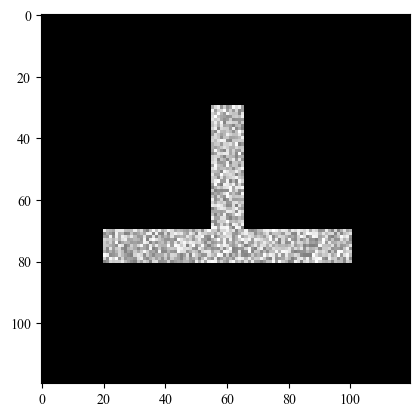

In [ ]:
from skimage.draw import random_shapes, rectangle

rng = np.random.default_rng(120)

img = np.zeros((120,120), dtype=np.float32)
img0 = np.copy(img)

start = (70, 20)
end = (80, 100)
rr, cc = rectangle(start, end=end, shape=img.shape)
img0[rr, cc] = 1

fill_val = 0.5 * rng.random([81,11]) + 0.5
img[rr, cc] = fill_val

start = (30, 55)
end = (70, 65)
rr, cc = rectangle(start, end=end, shape=img.shape)
img0[rr, cc] = 1

fill_val = 0.5 * rng.random([11,41]) + 0.5
img[rr, cc] = fill_val

plt.imshow(img, cmap='gray')

In [4]:
def soft_skeletonize(x, thresh_width=10):
    '''
    Differenciable aproximation of morphological skelitonization operaton
    thresh_width - maximal expected width of vessel
    '''
    for i in range(thresh_width):
        min_pool_x = torch.nn.functional.max_pool2d(x * -1, (3, 3), 1, 1) * -1
        contour = torch.nn.functional.relu(torch.nn.functional.max_pool2d(min_pool_x, (3, 3), 1, 1) - min_pool_x)
        x = torch.nn.functional.relu(x - contour)
    return x

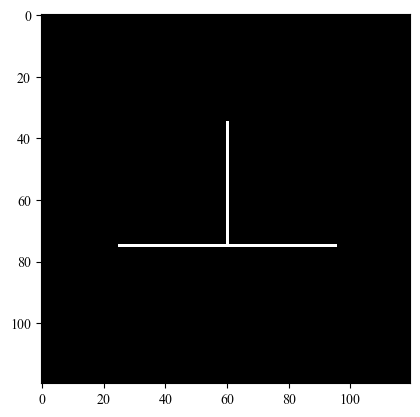

In [5]:
img_t = np.expand_dims(img0,axis=0) 
skel02 = soft_skeletonize(torch.from_numpy(img_t), thresh_width=10)
skel02 = np.squeeze(skel02.numpy())
plt.imshow(skel02, cmap='gray')

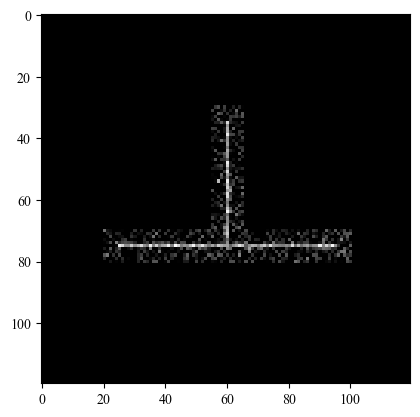

In [6]:
img_t = np.expand_dims(img,axis=0) 
skel2n = soft_skeletonize(torch.from_numpy(img_t), thresh_width=10)
skel2n = np.squeeze(skel2n.numpy())
plt.imshow(skel2n, cmap='gray')

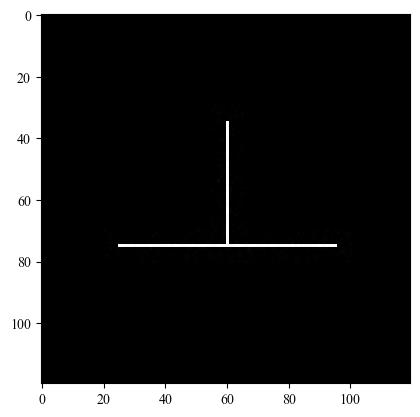

In [7]:
img_p = np.power(img,1/32 )

img_t = np.expand_dims(img_p,axis=0) 
skel2 = soft_skeletonize(torch.from_numpy(img_t), thresh_width=15)
skel2 = np.squeeze(skel2.numpy())
plt.imshow(skel2, cmap='gray')

In [ ]:
from skimage.morphology import square, cube, disk, ball
def get_tsp_map(pred_skel,neigh_r=2):
    """
    All computations can be reimplemented using PyTorch.
    """
    # pred_skel = skmor.skeletonize(mask_pred, method='lee')
    
    kernel = square(3)
    kernel[1,1] = 0
    pred_kp = ndimage.convolve(pred_skel, kernel, mode='constant', cval=0.0)

    pred_kp = ( np.maximum(0, pred_kp -2) + np.maximum(0, 2 - pred_kp )) * pred_skel

    negih_kernel = disk(neigh_r)
    pred_tsp = ndimage.convolve(pred_kp, negih_kernel, mode='constant', cval=0.0)
    

    
    return pred_tsp

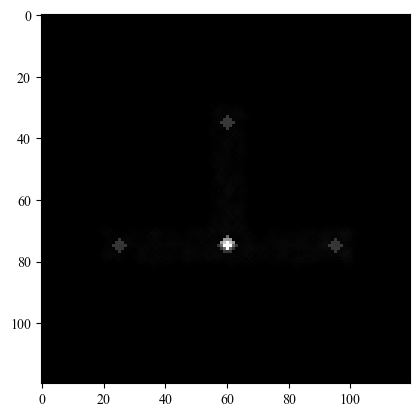

In [10]:
kp2 = get_tsp_map(skel2,neigh_r=2)
plt.imshow(kp2, cmap='gray')